# 2 · Tokenizer evaluation

**Task 1a, compare tokenizers and quantify the Indic token overhead.**

Eight tokenizers spanning the three vocabulary designs a deployment actually
chooses between:

| design | tokenizers |
|---|---|
| English-centric byte BPE | GPT-4 `cl100k`, GPT-4o `o200k`, BLOOMZ |
| multilingual SentencePiece | mBART-50, mT5 |
| Indic-specialised | IndicBART, MuRIL, Sarvam-1 |

Three questions, three families of metric:

- **How verbose is it?** `fertility` (tokens per word) and `chars_per_token`.
- **What does Devanagari cost specifically?** `parity`, Hindi tokens divided by
  English tokens *for the same judgment*. This is what turns into context and
  money.
- **Is it lossless?** A low fertility bought by dropping characters is no saving.

Two tokenizers named in the brief are absent for recorded reasons: **SUTRA**
publishes no tokenizer artefact (API only), and **IndicBERT**'s repo is now
access-restricted. Both stay in `configs/tokenizers.yaml` marked `skip` rather
than being quietly dropped.

Input is the 25 pairs that survive the quality gate in notebook 1.

In [1]:
from court_mt.notebook import setup

theme = setup()

In [2]:
import pandas as pd

from court_mt import paths, viz
from court_mt.corpus.dataset import load_corpus
from court_mt.tokenization.benchmark import run
from court_mt.tokenization.registry import load_adapters, load_specs

judgments = load_corpus()
adapters = load_adapters(load_specs(paths.CONFIGS / "tokenizers.yaml"))

summary, per_document = run(adapters, judgments)
summary.to_csv(paths.REPORTS / "tokenizer_summary.csv", index=False)
per_document.to_csv(paths.REPORTS / "tokenizer_per_document.csv", index=False)

print(f"{len(adapters)} tokenizers x {len(judgments)} judgments")

INFO    court_mt.tokenization.registry: loaded gpt4-cl100k            vocab= 100277


INFO    court_mt.tokenization.registry: loaded gpt4o-o200k            vocab= 200019


/Users/karan/Desktop/adalat-court-mt/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO    court_mt.tokenization.registry: loaded bloomz-560m            vocab= 250680


INFO    court_mt.tokenization.registry: loaded mbart-50               vocab= 250054


You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


... (13 outputs left out)

tokenizers:  88%|████████▊ | 7/8 [00:23<00:03,  3.82s/it]

tokenizers: 100%|██████████| 8/8 [00:25<00:00,  3.09s/it]

tokenizers: 100%|██████████| 8/8 [00:25<00:00,  3.18s/it]

8 tokenizers x 25 judgments


## The headline table

Sorted by Hindi fertility. Ratios are ratio-of-sums over the whole corpus, not
the mean of per-document ratios, otherwise a two-page order would count as much
as a forty-page judgment.

In [3]:
headline = summary.set_index("label")[[
    "vocab_size", "en_fertility", "hi_fertility", "parity",
    "hi_chars_per_token", "hi_whole_word_rate",
]]
headline.columns = ["vocab", "EN fertility", "HI fertility", "parity", "HI chars/token", "HI whole words"]
headline

,vocab,EN fertility,HI fertility,parity,HI chars/token,HI whole words
label,,,,,,
MuRIL (197k WP),197285,1.290,1.249,1.008,4.156,0.920
IndicBART (64k SP),64014,1.436,1.279,0.928,4.058,0.889
BLOOMZ (250k BPE),250680,1.268,1.308,1.075,3.967,0.878
mBART-50 (250k SP),250054,1.382,1.389,1.047,3.736,0.818
Sarvam-1 (68k),68096,1.564,1.496,0.996,3.470,0.799
GPT-4o / o200k_base,200019,1.273,1.627,1.331,3.191,0.675
mT5 (250k SP),250100,1.493,1.968,1.373,2.638,0.376
GPT-4 / cl100k_base,100277,1.277,4.986,4.066,1.041,0.002


## The Indic penalty

Parity of 1.0 means the vocabulary spends the same budget on both languages.
Above 1.0 is a pure encoding tax: notebook 1 established the Hindi text is
slightly *shorter* than the English in characters, so any excess is the script
being encoded badly, not a longer document.

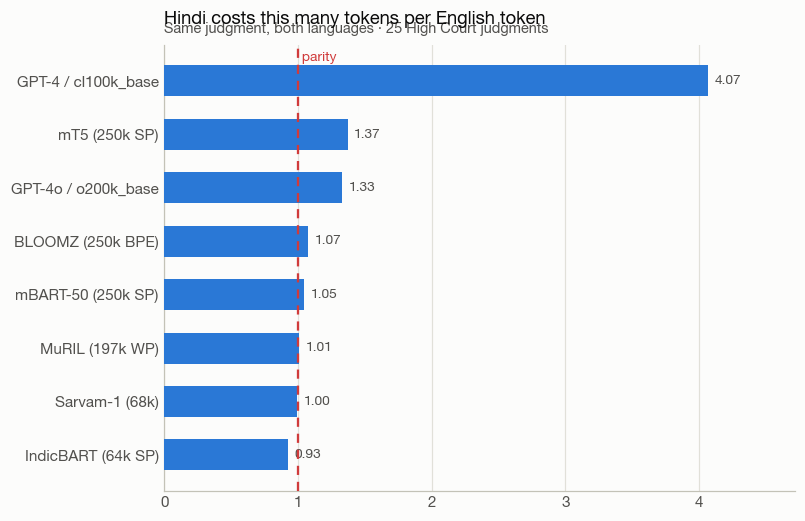

In [4]:
parity = summary.set_index("label")["parity"].sort_values(ascending=False)

axis = viz.ranked_bar(
    parity,
    title="Hindi costs this many tokens per English token",
    subtitle="Same judgment, both languages · 25 High Court judgments",
    reference=1.0,
    reference_label="parity",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "parity_by_tokenizer.png");

`cl100k` is the outlier by an order of magnitude, and the `HI chars/token` column
names the cause: it carries **1.04 characters per token** on Devanagari. That is
the signature of byte fallback, the script has almost no dedicated merges, so
each character decomposes into its three UTF-8 bytes and a token buys barely one
character.

`o200k` shows what a deliberately multilingual vocabulary buys on the same
architecture: parity falls from 4.07 to 1.33 with no change in approach.

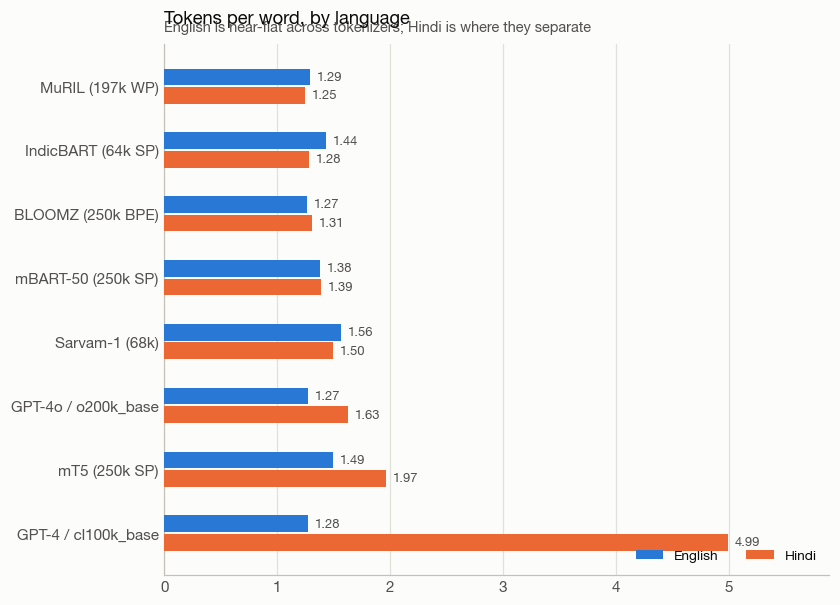

In [5]:
fertility = summary.set_index("label")[["en_fertility", "hi_fertility"]]
fertility.columns = ["English", "Hindi"]
fertility = fertility.sort_values("Hindi")

axis = viz.grouped_bar(
    fertility,
    title="Tokens per word, by language",
    subtitle="English is near-flat across tokenizers; Hindi is where they separate",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "fertility_by_language.png");

In [6]:
spread = lambda s: s.max() / s.min() - 1
print(f"English fertility: {summary.en_fertility.min():.3f}-{summary.en_fertility.max():.3f} "
      f"({spread(summary.en_fertility):.0%} spread)")
print(f"Hindi   fertility: {summary.hi_fertility.min():.3f}-{summary.hi_fertility.max():.3f} "
      f"({spread(summary.hi_fertility):.0%} spread)")

English fertility: 1.268-1.564 (23% spread)
Hindi   fertility: 1.249-4.986 (299% spread)


Every one of these tokenizers is trained heavily on English, so English fertility
sits in a narrow band. Hindi is where they diverge, **the choice of tokenizer is
almost entirely a choice about the Indic side.**

## What it costs in context and compute

Token counts become concrete at the context window. mBART and IndicBART cap their
encoder at 1024 positions; most small decoder LLMs sit at 4k.

In [7]:
context = summary.set_index("label")[[
    "hi_mean_tokens_per_doc", "hi_p95_tokens_per_doc", "hi_max_tokens_per_doc",
    "hi_fit_1024", "hi_fit_4096", "hi_fit_8192",
]].sort_values("hi_mean_tokens_per_doc")
context.columns = ["mean", "p95", "max", "fits 1024", "fits 4096", "fits 8192"]
context

,mean,p95,max,fits 1024,fits 4096,fits 8192
label,,,,,,
MuRIL (197k WP),1951.240,3059.600,3803,0.040,1.000,1.000
IndicBART (64k SP),1998.320,3146.400,3939,0.000,1.000,1.000
BLOOMZ (250k BPE),2044.040,3192.400,3972,0.000,1.000,1.000
mBART-50 (250k SP),2170.600,3398.600,4336,0.000,0.960,1.000
Sarvam-1 (68k),2336.880,3735.600,4592,0.000,0.960,1.000
GPT-4o / o200k_base,2541.280,3973.400,4933,0.000,0.960,1.000
mT5 (250k SP),3074.240,4862.400,6124,0.000,0.800,1.000
GPT-4 / cl100k_base,7790.360,12206.200,15591,0.000,0.040,0.560


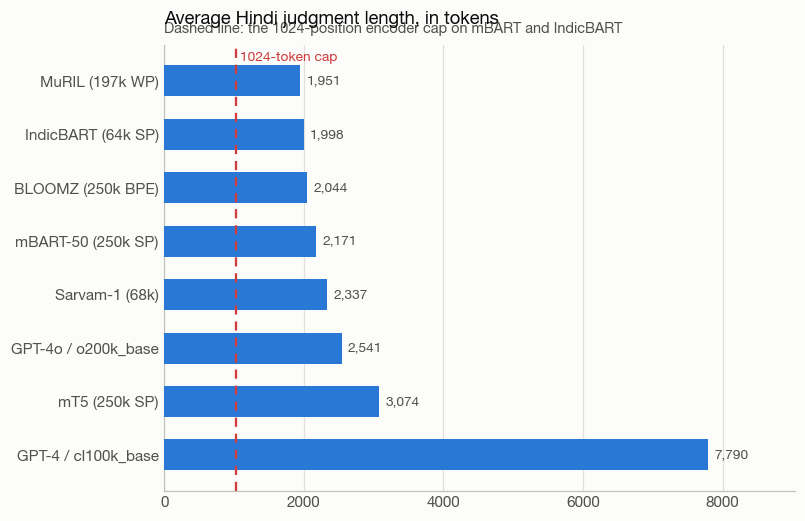

In [8]:
mean_tokens = summary.set_index("label")["hi_mean_tokens_per_doc"].sort_values()

axis = viz.ranked_bar(
    mean_tokens,
    title="Average Hindi judgment length, in tokens",
    subtitle="Dashed line: the 1024-position encoder cap on mBART and IndicBART",
    value_format="{:,.0f}",
    reference=1024,
    reference_label="1024-token cap",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "tokens_per_document.png");

**Essentially no judgment fits a 1024-token encoder under any tokenizer.**
Chunking is not an optimisation for Task 3, it is a precondition, and the
tokenizer decides how many chunks, which decides how much cross-sentence context
the model loses.

Cost splits into two indices because prefill has two terms. Billing and the
feed-forward path are linear in tokens; attention is quadratic, and at judgment
length the quadratic term is what bites.

In [9]:
cost = summary.set_index("label")[[
    "hi_token_cost_index", "hi_attention_cost_index", "hi_usd_per_corpus_pass",
]].sort_values("hi_token_cost_index")
cost.columns = ["token cost (x)", "attention cost (x)", "USD per corpus pass"]

print(f"indexed against {summary.attrs['baseline_tokenizer']}, the cheapest on Hindi\n")
cost

indexed against muril, the cheapest on Hindi



,token cost (x),attention cost (x),USD per corpus pass
label,,,
MuRIL (197k WP),1.000,1.000,0.122
IndicBART (64k SP),1.024,1.054,0.125
BLOOMZ (250k BPE),1.048,1.098,0.128
mBART-50 (250k SP),1.112,1.245,0.136
Sarvam-1 (68k),1.198,1.435,0.146
GPT-4o / o200k_base,1.302,1.690,0.159
mT5 (250k SP),1.576,2.502,0.192
GPT-4 / cl100k_base,3.993,16.017,0.487


The gap between the two columns is the point. `cl100k` costs 4x the tokens but
**16x the attention compute**, because squaring a per-document length is not the
same as scaling a total.

## Fidelity, is the saving real?

Two questions, deliberately not merged:

- **`chars preserved`**, do we get every character back? This is data loss.
- **`spacing preserved`**, do we get the original *spacing* back? A
  detokenisation cost: bad for legal formatting, but nothing is lost.

In [10]:
fidelity = summary.set_index("label")[[
    "hi_unk_rate", "hi_roundtrip_ok", "hi_spacing_ok", "hi_vocab_utilization", "hi_renyi_efficiency",
]]
fidelity.columns = ["HI unk rate", "chars preserved", "spacing preserved", "vocab used", "Rényi efficiency"]
fidelity

,HI unk rate,chars preserved,spacing preserved,vocab used,Rényi efficiency
label,,,,,
MuRIL (197k WP),0.000,True,False,0.019,0.370
IndicBART (64k SP),0.000,False,False,0.057,0.415
BLOOMZ (250k BPE),0.000,True,True,0.016,0.371
mBART-50 (250k SP),0.000,True,False,0.013,0.382
Sarvam-1 (68k),0.000,True,True,0.047,0.416
GPT-4o / o200k_base,0.000,True,True,0.013,0.400
mT5 (250k SP),0.000,True,False,0.010,0.304
GPT-4 / cl100k_base,0.000,True,True,0.004,0.290


Every tokenizer reports a zero unknown rate, so `<unk>` is not where losses hide, which is exactly why the round-trip check exists.

IndicBART is the one that genuinely drops characters: its SentencePiece
normaliser collapses the doubled apostrophes these judgments use to quote defined
terms. MuRIL preserves every character but re-spaces punctuation on every
document, which a legal-formatting pipeline would have to repair.

In [11]:
import unicodedata

indicbart = next(a for a in adapters if a.key == "indicbart")
sample = "न्यायालय ने (''एफआईआर'') दर्ज करने का निर्देश दिया।"
restored = indicbart.decode(indicbart.encode(sample))

print("in :", sample)
print("out:", restored)
for character in sorted(set(sample) - set(restored)):
    print(f"\ndropped U+{ord(character):04X}  {unicodedata.name(character, '?')}")

in : न्यायालय ने (''एफआईआर'') दर्ज करने का निर्देश दिया।
out: न्यायालय ने ("एफआईआर") दर्ज करने का निर्देश दिया।

dropped U+0027  APOSTROPHE


## Qualitative view, where the tokens actually go

A single sentence of statutory Hindi, segmented by each tokenizer. `_` marks a
SentencePiece word boundary. Fragmentation is far easier to see than to read off
a ratio.

In [12]:
probe = "अपीलार्थी ने भारतीय दण्ड संहिता की धारा 302 के अन्तर्गत याचिका दायर की।"

print(f"{probe}\n{len(probe)} characters, {len(probe.split())} words\n")
for adapter in sorted(adapters, key=lambda a: len(a.encode(probe))):
    pieces = adapter.pieces(probe)
    shown = " ".join(p.replace("\u2581", "_") for p in pieces[:20])
    print(f"{adapter.label:22s} {len(pieces):4d}  {shown}{' …' if len(pieces) > 20 else ''}")

अपीलार्थी ने भारतीय दण्ड संहिता की धारा 302 के अन्तर्गत याचिका दायर की।
71 characters, 13 words

MuRIL (197k WP)          15  अपील ##ार्थी ने भारतीय दण्ड संहिता की धारा 302 के अन्तर्गत याचिका दायर की ।
BLOOMZ (250k BPE)        16  अप ील ार्थी  ने  भारतीय  दण्ड  संहिता  की  धारा  302  के  अन्तर्गत  याचिका  दायर  की ।
IndicBART (64k SP)       16  _अपील ार्थी _ने _भारतीय _दण्ड _संहिता _की _धारा _30 2 _के _अन्तर्गत _याचिका _दायर _की ।
mBART-50 (250k SP)       17  _अपील ार्थी _ने _भारतीय _द ण्ड _ संहिता _की _धारा _302 _के _अन्तर्गत _याचिका _दायर _की ।
Sarvam-1 (68k)           24  _अप ी ला र्थी _ने _भारतीय _द ण्ड _सं हिता _की _धारा _ 3 0 2 _के _अन ्त र्गत …
GPT-4o / o200k_base      26  अप ील ार्थ ी  ने  भारतीय  द ण्ड  सं ह िता  की  ध ारा   302  के  अन्त र्गत  य …
mT5 (250k SP)            26  _अप ील ार्थी _ने _ भारतीय _द ण्ड _सं हि ता _की _ धारा _302 _के _ अन्तर्गत _ याच …
GPT-4 / cl100k_base      69  � � प ी ल ा� � ्� � ी  � � े  � � ा� � त ी � …


Watch `अपीलार्थी` ("the appellant"), a word that recurs throughout every judgment:
Indic-aware vocabularies keep it in one or two pieces, while `cl100k` shatters it
into byte fragments carrying no morpheme boundary at all.

## Which legal terms are most expensive

Ranking domain vocabulary by *total* tokens spent, frequency times cost per
occurrence, shows where a vocabulary budget would pay for itself. This ranking
is the input to the extension experiment in notebook 3.

In [13]:
from collections import Counter

from court_mt.corpus.dataset import texts
from court_mt.tokenization.metrics import words

baseline = next(a for a in adapters if a.key == "mbart-50")
frequencies = Counter(w for text in texts(judgments, "hi") for w in words(text))

expensive = pd.DataFrame([
    {
        "term": term,
        "count": count,
        "tokens_each": (n := len(baseline.encode(" " + term))),
        "tokens_total": count * n,
    }
    for term, count in frequencies.most_common(500)
])

print(f"ranked against {baseline.label}\n")
expensive.nlargest(15, "tokens_total").reset_index(drop=True)

ranked against mBART-50 (250k SP)



,term,count,tokens_each,tokens_total
0,के,2123,1,2123
1,की,993,1,993
2,में,975,1,975
3,है,950,1,950
4,को,870,1,870
5,और,724,1,724
6,से,618,1,618
7,कि,549,1,549
8,का,509,1,509
9,किया,488,1,488


## Findings

1. **Tokenizer choice is a Hindi decision.** English fertility varies 23% across
   the eight; Hindi fertility varies 299%.

2. **`cl100k` is unusable for Devanagari**, 4.07x parity, 4x the token bill and
   **16x the attention cost** of the best option, because Devanagari falls through
   to byte-level fallback at 1.04 characters per token. Only 4% of judgments fit
   a 4k context; for every other tokenizer it is 80, 100%.

3. **A large vocabulary is not the fix; a *relevant* one is.** IndicBART reaches
   parity 0.93 with 64k tokens, beating mT5's 250k (1.37) and matching models
   four times its size.

4. **Parity below 1.0 is achievable and correct.** IndicBART and Sarvam-1 encode
   Hindi slightly more cheaply than the matching English, the right outcome,
   since the Hindi text is shorter in characters.

5. **Cheap is not automatically lossless.** IndicBART drops quoting apostrophes;
   MuRIL, the fertility winner, re-spaces punctuation on every document.
   Neither is visible in a fertility number, and both matter for legal text.

6. **Chunking is mandatory for Task 3.** Essentially no judgment fits a
   1024-token encoder under any tokenizer.

Notebook 3 takes the best-placed candidates and tries to buy the remaining gap
back with domain vocabulary.